In [1]:
# add 1/f_sky into SZiFi, what is the change?

import numpy as np
import matplotlib.pyplot as plt
from pixell import enmap, utils, enplot, reproject, wcsutils
import szifi
from scipy import ndimage
from tqdm import tqdm

from scipy.spatial.distance import cdist
import os
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import gzip
from tqdm import tqdm

from pixell import enmap, utils, enplot, reproject
import szifi

import sys
sys.path.append("/shared_home/Ziyang/Cluster_Finder/")
from useful_code import *
from func_get_cata import *
import copy

In [2]:
seed = 0
cmb_seed = 0
tile_len = 8
mass_name = "highmass"
lmin = 1; lmax = 20000
q_th_noise = 4.0

cov_type = "anisotropic_gaussian"
kernel_shape = 3
it = 1
apotype = "C2"
aposcale = 25

noise_name = "mss2"

mask_type = "ps"

cata_dir_old = "catalogues_car_before_add_f_sky/"
cata_dir_new = "catalogues_car/"

cat_true = get_true_cata(seed, mass_type = "highmass")
N_true = cat_true.get_n_clusters()

In [3]:
def get_all_tiles_catalog_car_tens(mass_name = "highmass", noise_name = "white",seed = 0, it = 1, tile_len = 4, 
    cov_type = "anisotropic_gaussian", kernel_shape = 3,
    lmin = 1, lmax = 10000,
    apotype="C2", aposcale=6,  
    mask_type = "0", cata_dir = "catalogues_car/",
    radius_arcmin = 2, merge_mode = "masking_max",   
    q_th=5, q_th_noise=4.0):
    

    if cov_type == "anisotropic_gaussian":
        cat_path = "/shared_home/Ziyang/data/ten_realizations/"+cata_dir+\
mass_name+"_"+noise_name+"_"+cov_type+str(kernel_shape)+"_"+str(lmin)+"_"+str(lmax)+"_mask_"+mask_type+"_apo"+apotype+"_"+str(aposcale)+"/"
    elif cov_type == "isotropic":
        cat_path = "/shared_home/Ziyang/data/ten_realizations/"+cata_dir+mass_name+"_"+noise_name+"_isotropic_"+str(lmax)
    
    print("cat_path", cat_path)
    
    catname = "catalogue_find_"+str(it) 
    tileDef_file = "tileDefinitions_"+str(tile_len)+"deg_"+str(tile_len)+"deg.yml"
    field_ids = szifi.sphere.get_all_tile_names('/shared_home/Ziyang/Cluster_Finder/tileDefinitions/'+tileDef_file)
    results_dict = {}

    for i in tqdm(range(0, len(field_ids))):
        field_id = field_ids[i]
        cata_path = cat_path + "so_it_car_find_"+str(seed)+"_"+mass_name+"_"+noise_name+"_"+str(field_id)+".npy"

        if os.path.isfile(cata_path) == False: 
            print(field_id, cata_path)
            continue
        cat = np.load(cata_path, allow_pickle=1)[()]
        
        
        if i == 0 :
            theta_500_vec = cat[field_id].theta_500_vec[:]
    
        results_dict.update(cat)

    params_szifi = {"theta_500_vec_arcmin":theta_500_vec,
        "iterative":True}

    detection_processor = szifi.detection_processor(results_dict,params_szifi)
    
    cat  = detection_processor.results.catalogues[catname].catalogue
    ra  = np.rad2deg(cat["ra"]); ra[np.where(ra<0)]+=360
    dec = np.rad2deg(cat["dec"])
    cat["lon"] =ra
    cat["lat"] =dec
    cat['sn']  =cat["q_opt"]

    cat_all = thresh_merge(detection_processor, catname, \
                           merge_radius_arcmin=radius_arcmin, \
                           merge_mode=merge_mode,q_th_final=q_th)
    return cat_all, detection_processor

In [6]:
mask_type = "0"

cat_old = get_all_tiles_catalog_car_tens(mass_name = mass_name, noise_name=noise_name, seed = seed, 
    it=it, tile_len=tile_len, cov_type=cov_type, kernel_shape=kernel_shape,
    lmin=lmin, lmax=lmax, mask_type=mask_type, apotype = apotype, aposcale=aposcale, 
      cata_dir=cata_dir_old, q_th_noise=q_th_noise)[0]

cat_new = get_all_tiles_catalog_car_tens(mass_name = mass_name, noise_name=noise_name, seed = seed, 
    it=it, tile_len=tile_len, cov_type=cov_type, kernel_shape=kernel_shape,
    lmin=lmin, lmax=lmax, mask_type=mask_type, apotype = apotype, aposcale=aposcale, 
      cata_dir=cata_dir_new, q_th_noise=q_th_noise)[0]

cat_path /shared_home/Ziyang/data/ten_realizations/catalogues_car_before_add_f_sky/highmass_mss2_anisotropic_gaussian3_1_20000_mask_0_apoC2_25/


100%|██████████| 450/450 [00:00<00:00, 5295.24it/s]


cat_path /shared_home/Ziyang/data/ten_realizations/catalogues_car/highmass_mss2_anisotropic_gaussian3_1_20000_mask_0_apoC2_25/


100%|██████████| 450/450 [00:30<00:00, 14.69it/s]


In [23]:
seed = 9

cat_true = get_true_cata(seed, mass_type = "highmass")
cat_new = get_all_tiles_catalog_car_tens(mass_name = mass_name, noise_name=noise_name, seed = seed, 
    it=it, tile_len=tile_len, cov_type=cov_type, kernel_shape=kernel_shape,
    lmin=lmin, lmax=lmax, mask_type=mask_type, apotype = apotype, aposcale=aposcale, 
      cata_dir=cata_dir_new, q_th_noise=q_th_noise)[0]
cat_, cat_true_ = szifi.cat.identify_clusters_fast(catalogue_1=cat_new, catalogue_2=cat_true, id_radius_arcmin=1.,
                lonlat=True,mode="close+highest_q",sort=True,unique=True)
C, P = get_C_P(cat_, cat_true_, q_th = 5)
print(C, P)

cat_path /shared_home/Ziyang/data/ten_realizations/catalogues_car/highmass_mss2_anisotropic_gaussian3_1_20000_mask_0_apoC2_25/


100%|██████████| 450/450 [00:24<00:00, 18.62it/s]


debug: identify_clusters_fast
debug: build tree
debug: found neighbours


100%|██████████| 3287/3287 [00:00<00:00, 16653.11it/s]


0.9960728311317386 0.8487982963188317


In [7]:
cat_old.get_n_clusters(), cat_new.get_n_clusters()

(3822, 3330)

In [8]:
# C, P

for cat in [cat_old, cat_new]:
    cat_, cat_true_ = szifi.cat.identify_clusters_fast(catalogue_1=cat, catalogue_2=cat_true, id_radius_arcmin=1.,
                lonlat=True,mode="close+highest_q",sort=True,unique=True)
    C, P = get_C_P(cat_, cat_true_, q_th = 5)
    print(C, P)
    

debug: identify_clusters_fast
debug: build tree
debug: found neighbours


100%|██████████| 3822/3822 [00:00<00:00, 15988.88it/s]


0.9992846924177397 0.7310308738880168
debug: identify_clusters_fast
debug: build tree
debug: found neighbours


100%|██████████| 3330/3330 [00:00<00:00, 15701.25it/s]

0.9992846924177397 0.8390390390390391


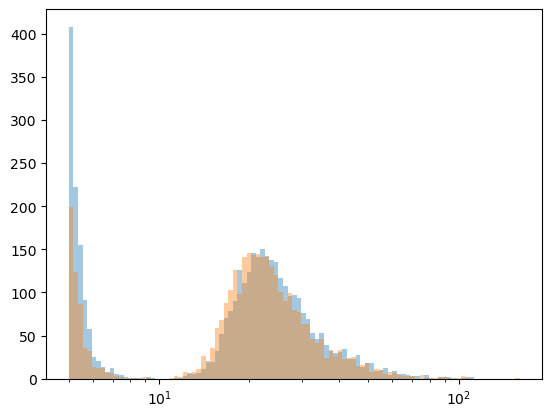

In [13]:
# N(q_opt)
fig, ax = plt.subplots()

bins = np.logspace(np.log10(5), np.log10(160), 100)
ax.hist(cat_old.catalogue["q_opt"], bins=bins, alpha = 0.4)
ax.hist(cat_new.catalogue["q_opt"], bins=bins, alpha = 0.4)
ax.set_xscale("log")